In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn.preprocessing import StandardScaler
from scipy.stats import pearsonr
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

warnings.filterwarnings('ignore')

### EDA

In [2]:
df = pd.read_csv('./insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [3]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
df.tail()

,age,sex,bmi,children,smoker,region,charges
1333,50,male,30.97,3,no,northwest,10600.5483
1334,18,female,31.92,0,no,northeast,2205.9808
1335,18,female,36.85,0,no,southeast,1629.8335
1336,21,female,25.80,0,no,southwest,2007.9450
1337,61,female,29.07,0,yes,northwest,29141.3603


In [5]:
df.shape

(1338, 7)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [7]:
df[df.duplicated()]

,age,sex,bmi,children,smoker,region,charges
581,19,male,30.59,0,no,northwest,1639.5631


In [8]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [9]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [10]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')

In [11]:
df["region"].unique()

<StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str

In [12]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')

In [13]:
pd.get_dummies(df, columns=["region"], dtype=int).columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'],
      dtype='str')

In [14]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [15]:
df["sex"].map({"female": 1, "male": 0})

0       1
1       0
2       0
3       0
4       0
       ..
1333    0
1334    1
1335    1
1336    1
1337    1
Name: sex, Length: 1338, dtype: int64

In [16]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [17]:
df.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'],
      dtype='str')

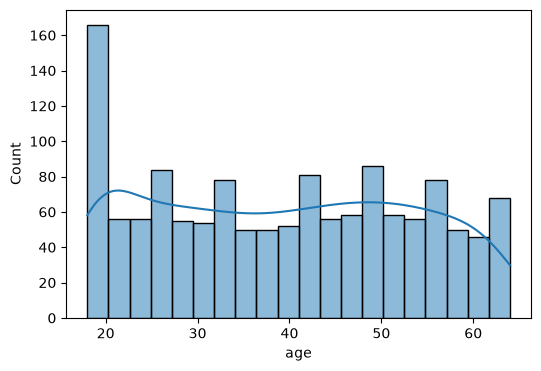

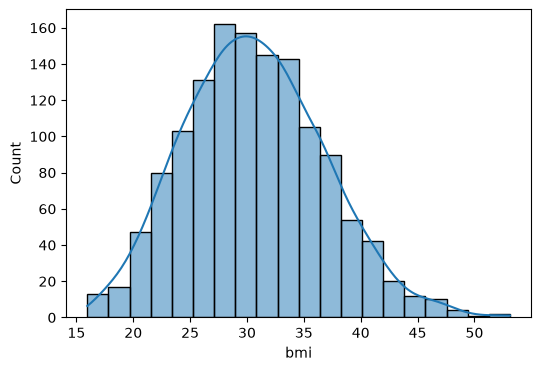

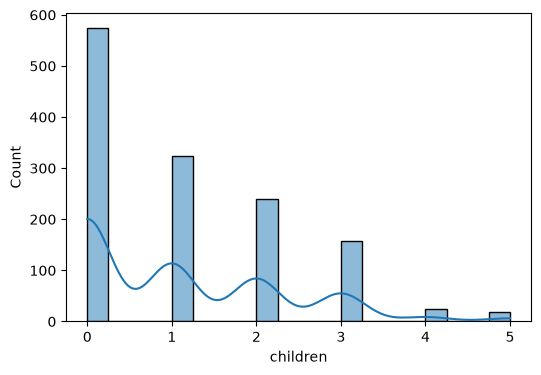

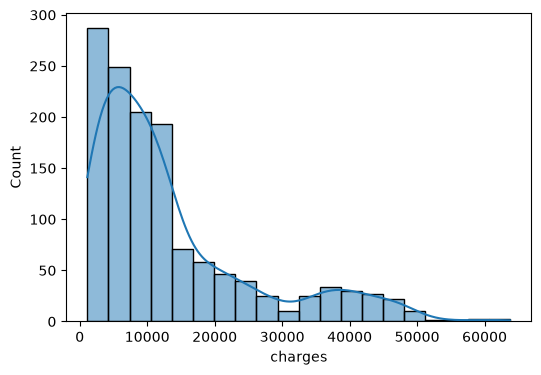

In [18]:
numeric_cols = ["age", "bmi", "children", "charges"]
for col in numeric_cols:
  plt.figure(figsize=(6,4))
  sns.histplot(df[col], kde=True, bins=20)

<Axes: xlabel='children', ylabel='count'>

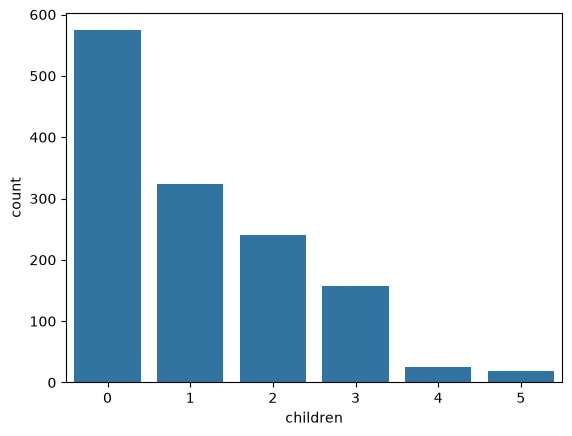

In [19]:
sns.countplot(x=df["children"])

<Axes: xlabel='sex', ylabel='count'>

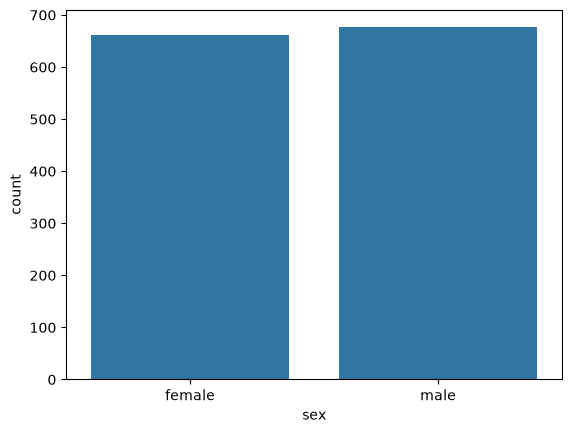

In [20]:
sns.countplot(x=df["sex"])

<Axes: xlabel='smoker', ylabel='count'>

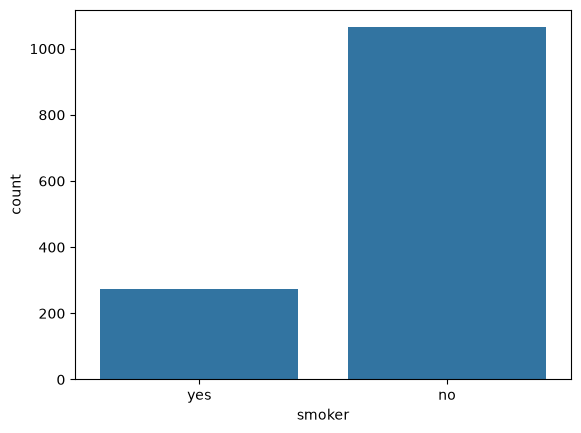

In [21]:
sns.countplot(x=df.smoker)

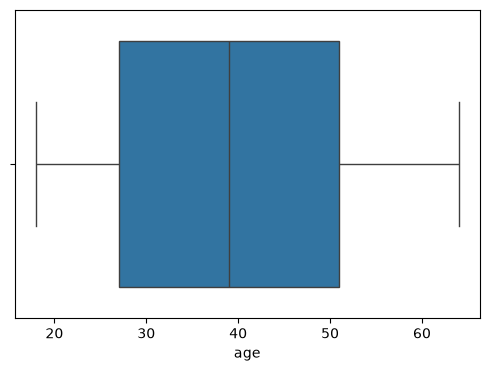

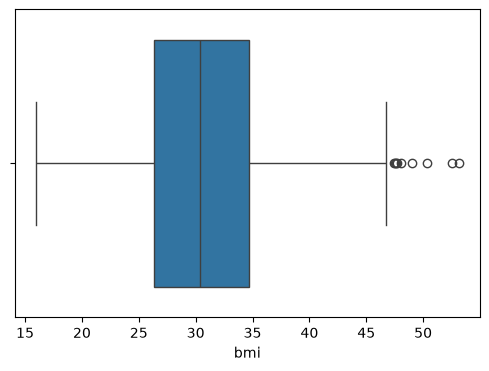

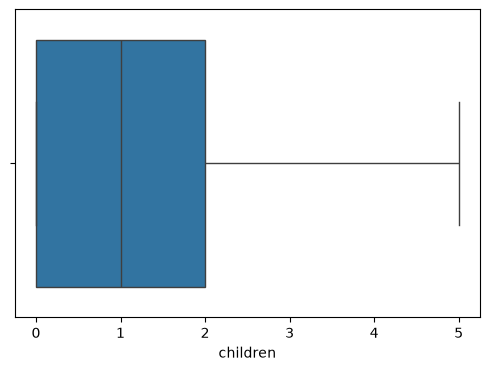

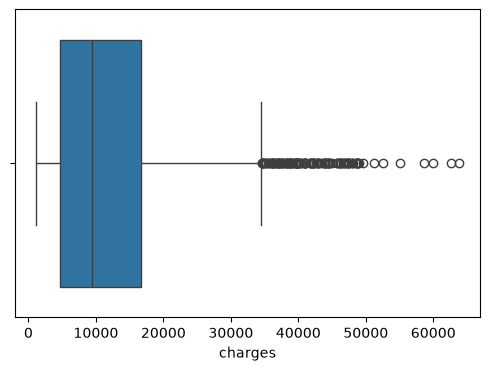

In [22]:
for col in numeric_cols:
  plt.figure(figsize=(6,4))
  sns.boxplot(x=df[col])

<Axes: >

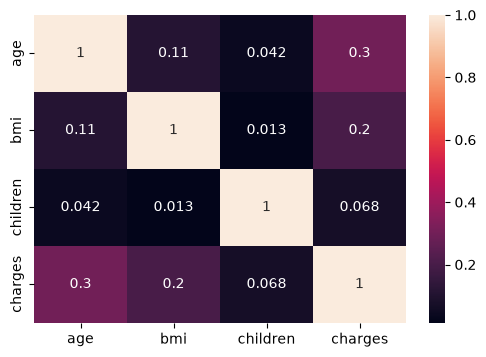

In [23]:
plt.figure(figsize=(6,4))
sns.heatmap(df[numeric_cols].corr(), annot=True)

<Axes: >

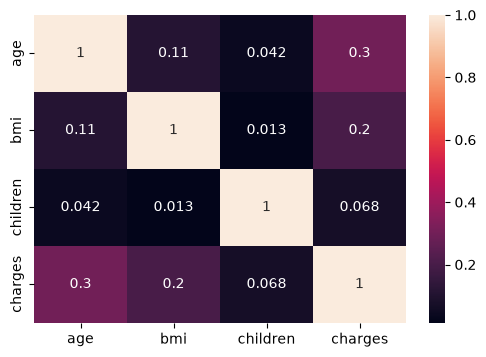

In [24]:
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(numeric_only=True), annot=True)

### Data cleaning and preprocessing

In [25]:
df_cleaned = df.copy()

In [26]:
df_cleaned

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [27]:
df_cleaned = pd.get_dummies(df_cleaned, columns=["region"], dtype=int)
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,16884.92400,0,0,0,1
1,18,male,33.770,1,no,1725.55230,0,0,1,0
2,28,male,33.000,3,no,4449.46200,0,0,1,0
3,33,male,22.705,0,no,21984.47061,0,1,0,0
4,32,male,28.880,0,no,3866.85520,0,1,0,0


In [28]:
df_cleaned.drop_duplicates(inplace=True)

In [29]:
df_cleaned.shape

(1337, 10)

In [30]:
df_cleaned.dtypes

age                   int64
sex                     str
bmi                 float64
children              int64
smoker                  str
charges             float64
region_northeast      int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
dtype: object

In [31]:
df["sex"].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [32]:
df_cleaned.columns

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest'],
      dtype='str')

In [33]:
df_cleaned["sex"] = df_cleaned["sex"].map({"male": 0, "female": 1})

In [34]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,yes,16884.92400,0,0,0,1
1,18,0,33.770,1,no,1725.55230,0,0,1,0
2,28,0,33.000,3,no,4449.46200,0,0,1,0
3,33,0,22.705,0,no,21984.47061,0,1,0,0
4,32,0,28.880,0,no,3866.85520,0,1,0,0


In [35]:
df_cleaned["sex"].dtypes

dtype('int64')

In [36]:
df_cleaned["sex"].value_counts()

sex
0    675
1    662
Name: count, dtype: int64

In [37]:
df_cleaned["smoker"].value_counts()

smoker
no     1063
yes     274
Name: count, dtype: int64

In [38]:
df_cleaned["smoker"] = df_cleaned["smoker"].map({"no": 0, "yes": 1})

In [39]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


In [40]:
df_cleaned.rename(columns={
  "sex": "is_female",
  "smoker": "is_smoker"
}, inplace=True)

In [41]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0


### Feature Engineering and Extraction

In [42]:
df_cleaned["bmi"].head()

0    27.900
1    33.770
2    33.000
3    22.705
4    28.880
Name: bmi, dtype: float64

<Axes: xlabel='bmi', ylabel='Count'>

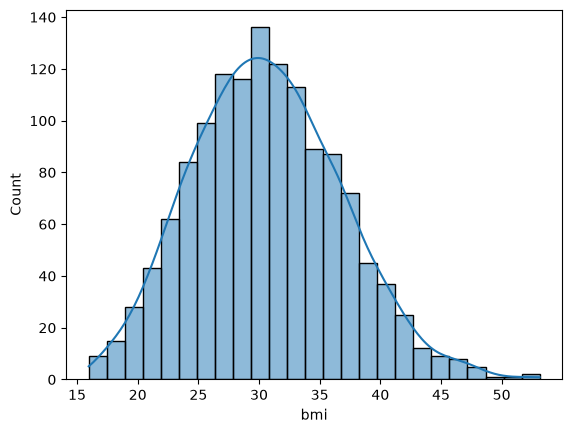

In [43]:
sns.histplot(df.bmi, kde=True)

In [44]:
bins = [0, 18.5, 24.9, 29.9, 100]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df_cleaned["bmi_category"] = pd.cut(df_cleaned["bmi"], bins=bins, labels=labels)

In [45]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category
0,19,1,27.900,0,1,16884.92400,0,0,0,1,Overweight
1,18,0,33.770,1,0,1725.55230,0,0,1,0,Obese
2,28,0,33.000,3,0,4449.46200,0,0,1,0,Obese
3,33,0,22.705,0,0,21984.47061,0,1,0,0,Normal
4,32,0,28.880,0,0,3866.85520,0,1,0,0,Overweight


In [46]:
df_cleaned = pd.get_dummies(df_cleaned, columns=["bmi_category"], dtype=int)
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27.900,0,1,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,0,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,0,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,0,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0,0,0,1,0


In [47]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese'],
      dtype='str')

In [48]:
df_cleaned.info()

<class 'pandas.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       1337 non-null   int64  
 1   is_female                 1337 non-null   int64  
 2   bmi                       1337 non-null   float64
 3   children                  1337 non-null   int64  
 4   is_smoker                 1337 non-null   int64  
 5   charges                   1337 non-null   float64
 6   region_northeast          1337 non-null   int64  
 7   region_northwest          1337 non-null   int64  
 8   region_southeast          1337 non-null   int64  
 9   region_southwest          1337 non-null   int64  
 10  bmi_category_Underweight  1337 non-null   int64  
 11  bmi_category_Normal       1337 non-null   int64  
 12  bmi_category_Overweight   1337 non-null   int64  
 13  bmi_category_Obese        1337 non-null   int64  
dtypes: float64(2), int64(12)

In [49]:
scaler = StandardScaler()
cols = ["age", "bmi", "children"]
df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [50]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0


In [51]:
selected_features = [
  'age', 'is_female', 'bmi', 'children', 'is_smoker',
  'region_northeast', 'region_northwest', 'region_southeast',
  'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
  'bmi_category_Overweight', 'bmi_category_Obese']

correlations = {
  feature: pearsonr(df_cleaned[feature], df_cleaned["charges"])[0] for feature in selected_features
}
correlations

{'age': np.float64(0.29830821250978634),
 'is_female': np.float64(-0.05804449579031288),
 'bmi': np.float64(0.19840083122624938),
 'children': np.float64(0.06738935083963249),
 'is_smoker': np.float64(0.7872343672800317),
 'region_northeast': np.float64(0.00594532327297934),
 'region_northwest': np.float64(-0.03869463262101644),
 'region_southeast': np.float64(0.07357792870627783),
 'region_southwest': np.float64(-0.04363736849776149),
 'bmi_category_Underweight': np.float64(-0.048224770768365136),
 'bmi_category_Normal': np.float64(-0.1056549118470303),
 'bmi_category_Overweight': np.float64(-0.118279404344456),
 'bmi_category_Obese': np.float64(0.1976593653842597)}

In [52]:
correlations.items()

dict_items([('age', np.float64(0.29830821250978634)), ('is_female', np.float64(-0.05804449579031288)), ('bmi', np.float64(0.19840083122624938)), ('children', np.float64(0.06738935083963249)), ('is_smoker', np.float64(0.7872343672800317)), ('region_northeast', np.float64(0.00594532327297934)), ('region_northwest', np.float64(-0.03869463262101644)), ('region_southeast', np.float64(0.07357792870627783)), ('region_southwest', np.float64(-0.04363736849776149)), ('bmi_category_Underweight', np.float64(-0.048224770768365136)), ('bmi_category_Normal', np.float64(-0.1056549118470303)), ('bmi_category_Overweight', np.float64(-0.118279404344456)), ('bmi_category_Obese', np.float64(0.1976593653842597))])

In [53]:
correlations_df = pd.DataFrame(list(correlations.items()), columns=["Feature", "Person Correlation"])
correlations_df

,Feature,Person Correlation
0,age,0.298308
1,is_female,-0.058044
2,bmi,0.198401
3,children,0.067389
4,is_smoker,0.787234
5,region_northeast,0.005945
6,region_northwest,-0.038695
7,region_southeast,0.073578
8,region_southwest,-0.043637
9,bmi_category_Underweight,-0.048225


In [54]:
correlations_df.sort_values(by="Person Correlation", ascending=False)

,Feature,Person Correlation
4,is_smoker,0.787234
0,age,0.298308
2,bmi,0.198401
12,bmi_category_Obese,0.197659
7,region_southeast,0.073578
3,children,0.067389
5,region_northeast,0.005945
6,region_northwest,-0.038695
8,region_southwest,-0.043637
9,bmi_category_Underweight,-0.048225


<Axes: >

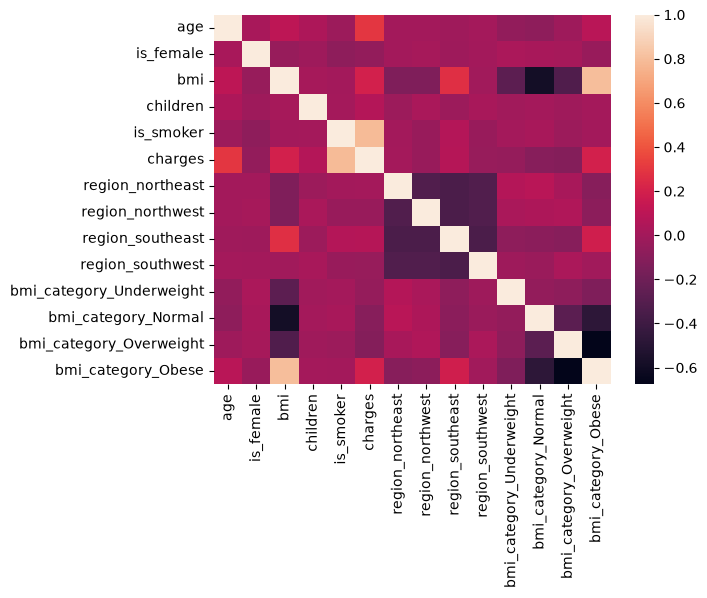

In [55]:
sns.heatmap(df_cleaned.corr())

<Axes: xlabel='charges', ylabel='Count'>

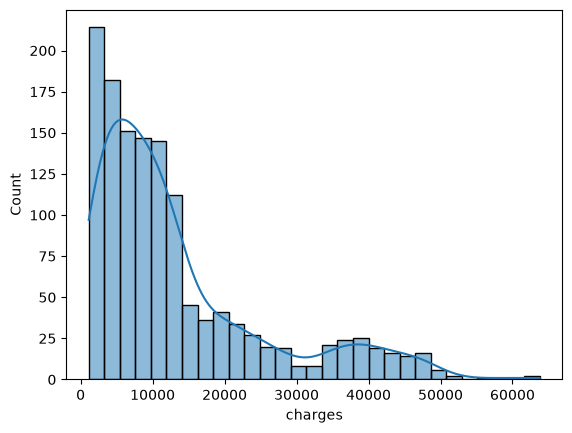

In [56]:
sns.histplot(df_cleaned["charges"], kde=True)

In [57]:
df_cleaned["charges_bin"] = pd.qcut(df_cleaned["charges"], q=4, labels=False)

In [58]:
df_cleaned["charges_bin"]

0       3
1       0
2       0
3       3
4       0
       ..
1333    2
1334    0
1335    0
1336    0
1337    3
Name: charges_bin, Length: 1337, dtype: int64

In [59]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_Underweight,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese,charges_bin
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,0,0,1,0,0,1,0,3
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,0,0,1,0,0,0,0,1,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,0,0,1,0,0,0,0,1,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,1,0,0,0,1,0,0,3
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.767704,0,0.050269,1.580143,0,10600.54830,0,1,0,0,0,0,0,1,2
1334,-1.511647,1,0.206053,-0.909234,0,2205.98080,1,0,0,0,0,0,0,1,0
1335,-1.511647,1,1.014490,-0.909234,0,1629.83350,0,0,1,0,0,0,0,1,0
1336,-1.297958,1,-0.797524,-0.909234,0,2007.94500,0,0,0,1,0,0,1,0,0


In [60]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese', 'charges_bin'],
      dtype='str')

In [61]:
cat_features = [
  'is_female', 'is_smoker',
  'region_northeast', 'region_northwest', 'region_southeast',
  'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
  'bmi_category_Overweight', 'bmi_category_Obese']
alpha = 0.05
chi2_results = {}

In [62]:
for col in cat_features:
  contingency = pd.crosstab(df_cleaned[col], df_cleaned["charges_bin"])
  chi2_stats, p_val, _, _ = chi2_contingency(contingency)
  decision = "Reject null (Keep Feature)" if p_val < alpha else "Accept Null (Drop Feature)"
  chi2_results[col] = {
    "chi2_stats": chi2_stats,
    "p_val": p_val,
    "decision": decision
  }

In [63]:
chi2_results

{'is_female': {'chi2_stats': np.float64(10.258784131896034),
  'p_val': np.float64(0.016489740254825715),
  'decision': 'Reject null (Keep Feature)'},
 'is_smoker': {'chi2_stats': np.float64(848.2191784691495),
  'p_val': np.float64(1.5074776554531107e-183),
  'decision': 'Reject null (Keep Feature)'},
 'region_northeast': {'chi2_stats': np.float64(6.438442307376374),
  'p_val': np.float64(0.09212205767134672),
  'decision': 'Accept Null (Drop Feature)'},
 'region_northwest': {'chi2_stats': np.float64(1.1342403613235656),
  'p_val': np.float64(0.76881540917986),
  'decision': 'Accept Null (Drop Feature)'},
 'region_southeast': {'chi2_stats': np.float64(15.998167448977355),
  'p_val': np.float64(0.0011349657141180654),
  'decision': 'Reject null (Keep Feature)'},
 'region_southwest': {'chi2_stats': np.float64(5.091893034250699),
  'p_val': np.float64(0.16519063312163623),
  'decision': 'Accept Null (Drop Feature)'},
 'bmi_category_Underweight': {'chi2_stats': np.float64(4.38474909501416

In [64]:
chi2_df = pd.DataFrame(chi2_results).T
chi2_df.sort_values(by="p_val", ascending=True, inplace=True)
chi2_df

,chi2_stats,p_val,decision
is_smoker,848.219178,0.0,Reject null (Keep Feature)
region_southeast,15.998167,0.001135,Reject null (Keep Feature)
is_female,10.258784,0.01649,Reject null (Keep Feature)
bmi_category_Obese,7.654464,0.05372,Accept Null (Drop Feature)
region_northeast,6.438442,0.092122,Accept Null (Drop Feature)
region_southwest,5.091893,0.165191,Accept Null (Drop Feature)
bmi_category_Underweight,4.384749,0.222804,Accept Null (Drop Feature)
bmi_category_Normal,4.263673,0.234364,Accept Null (Drop Feature)
bmi_category_Overweight,4.201575,0.240504,Accept Null (Drop Feature)
region_northwest,1.13424,0.768815,Accept Null (Drop Feature)


In [65]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_Underweight', 'bmi_category_Normal',
       'bmi_category_Overweight', 'bmi_category_Obese', 'charges_bin'],
      dtype='str')

In [66]:
final_df = df_cleaned[['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges', 'bmi_category_Obese', "region_southwest"]]
final_df

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Obese,region_southwest
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,1
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,1,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,1,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,0.050269,1.580143,0,10600.54830,1,0
1334,-1.511647,1,0.206053,-0.909234,0,2205.98080,1,0
1335,-1.511647,1,1.014490,-0.909234,0,1629.83350,1,0
1336,-1.297958,1,-0.797524,-0.909234,0,2007.94500,0,1


In [67]:
final_df.head()

,age,is_female,bmi,children,is_smoker,charges,bmi_category_Obese,region_southwest
0,-1.440418,1,-0.453160,-0.909234,1,16884.92400,0,1
1,-1.511647,0,0.509422,-0.079442,0,1725.55230,1,0
2,-0.799350,0,0.383155,1.580143,0,4449.46200,1,0
3,-0.443201,0,-1.305052,-0.909234,0,21984.47061,0,0
4,-0.514431,0,-0.292456,-0.909234,0,3866.85520,0,0


In [68]:
X = final_df.drop("charges", axis=1)
y = final_df["charges"]

In [69]:
X.head()

,age,is_female,bmi,children,is_smoker,bmi_category_Obese,region_southwest
0,-1.440418,1,-0.453160,-0.909234,1,0,1
1,-1.511647,0,0.509422,-0.079442,0,1,0
2,-0.799350,0,0.383155,1.580143,0,1,0
3,-0.443201,0,-1.305052,-0.909234,0,0,0
4,-0.514431,0,-0.292456,-0.909234,0,0,0


In [70]:
y

0       16884.92400
1        1725.55230
2        4449.46200
3       21984.47061
4        3866.85520
           ...     
1333    10600.54830
1334     2205.98080
1335     1629.83350
1336     2007.94500
1337    29141.36030
Name: charges, Length: 1337, dtype: float64

In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [72]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 3491.03, 44.68, 617.77,...,23026.71, 3092.4 , -325.72]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['age','is_female','bmi',...,'is_smoker','bmi_category_Obese', 'region_southwest']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6884
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [73]:
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
r2

0.8040114076644238

In [74]:
n = X_test.shape[0]
p = X_test.shape[1]

adjusted_r2 = 1 - ((1-r2) * (n-1) / (n - p - 1))
adjusted_r2

0.7987347917169275